# **NEXT WORD PREDICTION(SHONA)**


### 1. Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install PyPDF2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 3.4 MB/s eta 0:00:00


In [ ]:
import PyPDF2

def extract_text_from_pdf(pdf_path):
    with open(pdf_path, "rb") as file:
        reader = PyPDF2.PdfReader(file)
        text = "".join([page.extract_text() for page in reader.pages])
    return text

shona_text = extract_text_from_pdf("/content/drive/MyDrive/shona_text.pdf")

**PREPROCESSING TEXT**

In [ ]:
#words into lowecase
data = shona_text.lower()
print(data[450:538])

 
 
wayne anga avakushanda mudhorobha
riripedyo nedunhu ravo. kubvapaakapedza zvidzidzo 


In [ ]:
import re
#removing links
data = re.sub('https://\S+', '', data)
data = re.sub('www\S+', '', data)

In [ ]:
#REMOVING PUNCTUATIONS


punc = '''!()-[]{};:'"\,‘’“”<>./?@#$%^&*+_~→'''

for word in data:
  if word in punc:
    data = data.replace(word, "")



In [ ]:
# Removing the  words with digits

pattern = r'[0-9]'
data = re.sub(pattern, '', data)



### 2. Building Vocabulary of Unique Words

In [ ]:
from keras.preprocessing.text import Tokenizer

# Tokenize and preprocess
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])
total_words = len(tokenizer.word_index) + 1


**Saving Tokenizer**

In [ ]:
from pickle import dump

# save the tokenizer
dump(tokenizer, open( '/content/drive/MyDrive/tokenizer.pkl' , 'wb' ))

### 3. Word Embeddings

In [ ]:
from gensim.models import Word2Vec

# Train word2vec model with gensim
sentences = [sentence.split() for sentence in data.split('.')]
model_gensim = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)
model_gensim.save("word2vec.model")


**Bidirectional   RNN**

**Using its own embedding**

In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

model1 = Sequential()
model1.add(Embedding(total_words, 100, input_length=5))
model1.add(Bidirectional(LSTM(130, return_sequences=True)))
model1.add(Dropout(0.3))
model1.add(LSTM(90))
model1.add(Dense(total_words, activation='softmax'))

model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


**With pretrained embedding**

In [ ]:
# Load the word2vec model
import numpy as np
model_gensim = Word2Vec.load("word2vec.model")
embedding_matrix = np.zeros((total_words, 100))
for word, i in tokenizer.word_index.items():
    try:
        embedding_vector = model_gensim.wv[word]
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector
    except KeyError:

        pass


model2 = Sequential()
model2.add(Embedding(total_words, 100, weights=[embedding_matrix], input_length=5, trainable=False))
model2.add(Bidirectional(LSTM(150, return_sequences=True)))
model2.add(Dropout(0.2))
model2.add(LSTM(100))
model2.add(Dense(total_words, activation='softmax'))

model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


### 5. Training & Testing

In [ ]:
import keras
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

input_sequences = []
for line in shona_text.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

input_sequences = np.array(pad_sequences(input_sequences, maxlen=6, padding='pre'))
X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = keras.utils.to_categorical(y, num_classes=total_words)

# Split the dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42)

# Training Model 1
history1 = model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, verbose=1)

# Training Model 2
history2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, verbose=1)





Epoch 1/5
544/544 [==============================] - 61s 113ms/step - loss: 6.7411 - accuracy: 0.0549 - val_loss: 9.8439 - val_accuracy: 0.0405
Epoch 2/5
544/544 [==============================] - 64s 117ms/step - loss: 6.3306 - accuracy: 0.0640 - val_loss: 9.9094 - val_accuracy: 0.0413
Epoch 3/5
544/544 [==============================] - 64s 118ms/step - loss: 5.9258 - accuracy: 0.0783 - val_loss: 10.2869 - val_accuracy: 0.0438
Epoch 4/5
544/544 [==============================] - 63s 116ms/step - loss: 5.5392 - accuracy: 0.0945 - val_loss: 10.4705 - val_accuracy: 0.0426
Epoch 5/5
544/544 [==============================] - 65s 120ms/step - loss: 5.1702 - accuracy: 0.1183 - val_loss: 10.6368 - val_accuracy: 0.0453
Epoch 1/5
544/544 [==============================] - 62s 102ms/step - loss: 8.7606 - accuracy: 0.0284 - val_loss: 8.6926 - val_accuracy: 0.0300
Epoch 2/5
544/544 [==============================] - 54s 99ms/step - loss: 8.1997 - accuracy: 0.0286 - val_loss: 8.8774 - val_accurac

### Model Evaluation

In [ ]:
print(history1.history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


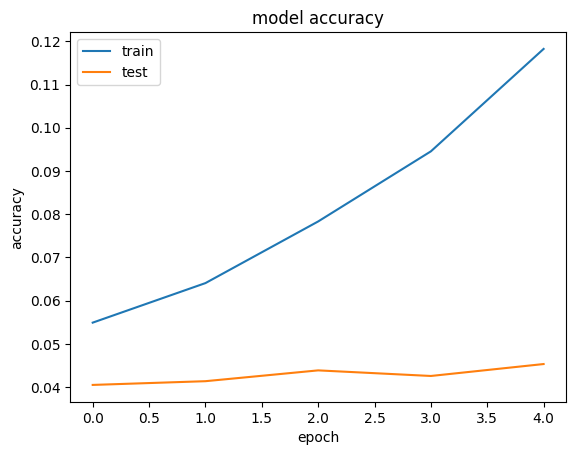

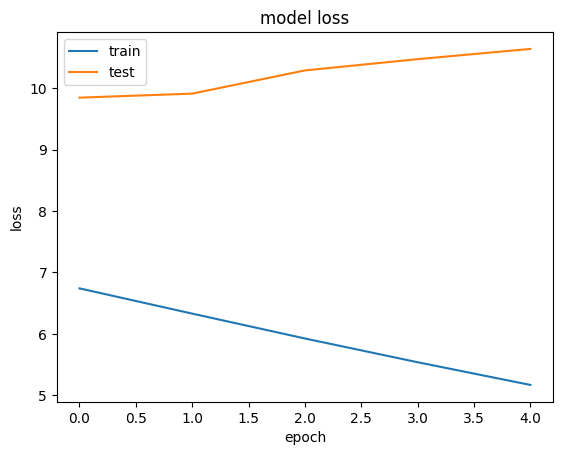

In [ ]:

import matplotlib.pyplot as plt
plt.plot(history1.history['accuracy'])
plt.plot(history1.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

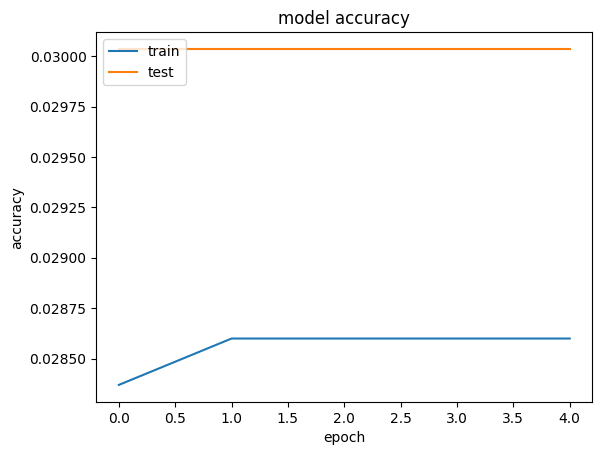

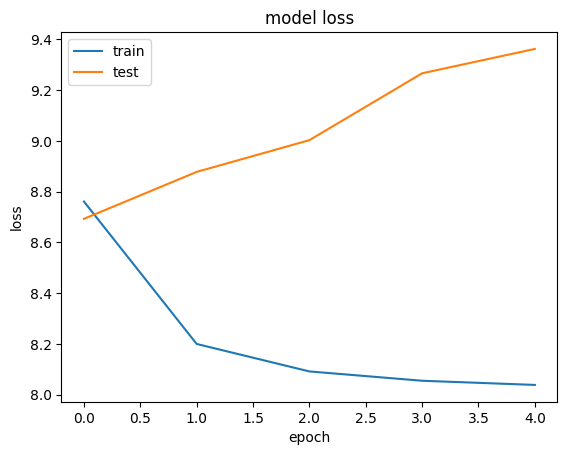

In [ ]:

plt.plot(history2.history['accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
val_loss_model1 = history1.history['val_loss'][-1]
val_loss_model2 = history2.history['val_loss'][-1]

print(f"Validation Loss for Model 1: {val_loss_model1}")
print(f"Validation Loss for Model 2: {val_loss_model2}")


Validation Loss for Model 1: 10.636795997619629
Validation Loss for Model 2: 9.361889839172363


Taking best model

In [ ]:
if val_loss_model1 < val_loss_model2:
    best_model = model1
    best_model_name = "best_model1.h5"
else:
    best_model = model2
    best_model_name = "best_model2.h5"

best_model.save(best_model_name)
print(f"Saved the best model as {best_model_name}")


Saved the best model as best_model2.h5


**PREDICTING NEXT WORD**

https://naturallanguageprocessing-xyj6ps4ezaorqsc8myiykp.streamlit.app/

**Using text box**

In [ ]:
from keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the previously saved model
model = load_model('best_model2.h5')

def predict_next_words(model, tokenizer, text, num_words=1):

    for _ in range(num_words):
        # Tokenize and pad the text
        sequence = tokenizer.texts_to_sequences([text])[0]
        sequence = pad_sequences([sequence], maxlen=5, padding='pre')

        # Predict the next word
        predicted_probs = model.predict(sequence, verbose=0)
        predicted = np.argmax(predicted_probs, axis=-1)

        # Convert the predicted word index to a word
        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break

        # Append the predicted word to the text
        text += " " + output_word

    return ' '.join(text.split(' ')[-num_words:])


# Prompt the user for input
user_input = input("Please type five words in Shona: ")

# Predict the next words
predicted_words = predict_next_words(model, tokenizer, user_input, num_words=3)
print(f"The next words might be: {predicted_words}")


Please type five words in Shona: maswera here munofara here imi
The next words might be: kuti anga ndanga
